# Coming from Spinach

Spynach keeps Spinach's structure: the same functions, called in the same
order, with the same arguments, field names, units, and tolerances. A
Spinach script translates into Spynach almost line by line. This page lists,
topic by topic, what carries over unchanged and what is different, and
what is not ported yet. The [Hilbert-space guide](hilbert-space.ipynb) explains each
function in full.

Every Python block on this page is executed by `tests/docs/`. MATLAB blocks
are Spinach code, shown for comparison and not run. The companion notebook
is [`notebooks/coming-from-spinach.ipynb`](coming-from-spinach.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/coming-from-spinach.ipynb)).

*Generated from [`docs/coming-from-spinach.md`](../coming-from-spinach.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [A Spinach script, translated](#A-Spinach-script,-translated)
2. [General differences](#General-differences)
3. [Spin system: `sys` and `inter`](#Spin-system:-sys-and-inter)
4. [Basis: `bas`](#Basis:-bas)
5. [Operators and states](#Operators-and-states)
6. [Assumptions and the Hamiltonian](#Assumptions-and-the-Hamiltonian)
7. [Experiment parameters](#Experiment-parameters)
8. [Calculation modalities](#Calculation-modalities)
9. [Processing and plotting](#Processing-and-plotting)
10. [Checking your own workflow against Spinach](#Checking-your-own-workflow-against-Spinach)
11. [Beyond the port](#Beyond-the-port)
12. [Messages and errors](#Messages-and-errors)

## A Spinach script, translated

Spinach's `examples/nmr_liquids/pa_styrene.m` simulates the 1H spectrum of
styrene at 7.046 T:

```matlab
sys.isotopes={'1H','1H','1H','1H','1H','1H','1H','1H'};
sys.magnet=7.046;
inter.zeeman.scalar={6.720  6.720  6.587  6.587  6.527  6.063   5.085  4.555};
inter.coupling.scalar={ 0.0  1.9170  7.7884  0.6061  1.2447 -0.5347  0.0390  0.1582
                        0.0  0.0     0.6061  7.7884  1.2447 -0.5347  0.0390  0.1582
                        0.0  0.0     0.0     1.4184  7.4390  0.3693 -0.0416  0.0169
                        0.0  0.0     0.0     0.0     7.4390  0.3693 -0.0416  0.0169
                        0.0  0.0     0.0     0.0     0.0    -0.2279  0.2349  0.2905
                        0.0  0.0     0.0     0.0     0.0     0.0    17.6002 10.8954
                        0.0  0.0     0.0     0.0     0.0     0.0     0.0     1.0382
                        0.0  0.0     0.0     0.0     0.0     0.0     0.0     0.0};
bas.formalism='zeeman-hilb';
bas.approximation='none';
spin_system=create(sys,inter);
spin_system=basis(spin_system,bas);
parameters.spins={'1H'};
parameters.rho0=state(spin_system,'L+','1H');
parameters.coil=state(spin_system,'L+','1H');
parameters.decouple={};
parameters.offset=1700;
parameters.sweep=1000;
parameters.npoints=16384;
parameters.zerofill=65536;
parameters.axis_units='ppm';
parameters.invert_axis=1;
fid=liquid(spin_system,@acquire,parameters,'nmr');
fid=apodisation(spin_system,fid,{{'gauss',6}});
spectrum=fftshift(fft(fid,parameters.zerofill));
kfigure(); plot_1d(spin_system,real(spectrum),parameters);
```

In Spynach:

In [1]:
import numpy as np
import spynach

sys = {"isotopes": ["1H"] * 8, "magnet": 7.046}
inter = {
    "zeeman": {"scalar": [6.720, 6.720, 6.587, 6.587, 6.527, 6.063, 5.085, 4.555]},
    "coupling": {"scalar": [
        [0.0, 1.9170, 7.7884, 0.6061, 1.2447, -0.5347,  0.0390,  0.1582],
        [0.0, 0.0,    0.6061, 7.7884, 1.2447, -0.5347,  0.0390,  0.1582],
        [0.0, 0.0,    0.0,    1.4184, 7.4390,  0.3693, -0.0416,  0.0169],
        [0.0, 0.0,    0.0,    0.0,    7.4390,  0.3693, -0.0416,  0.0169],
        [0.0, 0.0,    0.0,    0.0,    0.0,    -0.2279,  0.2349,  0.2905],
        [0.0, 0.0,    0.0,    0.0,    0.0,     0.0,    17.6002, 10.8954],
        [0.0, 0.0,    0.0,    0.0,    0.0,     0.0,     0.0,     1.0382],
        [0.0, 0.0,    0.0,    0.0,    0.0,     0.0,     0.0,     0.0],
    ]},
}
bas = {"formalism": "zeeman-hilb", "approximation": "none"}
spin_system = spynach.create(sys, inter)
spin_system = spynach.basis(spin_system, bas)

parameters = {
    "spins": ["1H"],
    "rho0": spynach.state(spin_system, "L+", "1H"),
    "coil": spynach.state(spin_system, "L+", "1H"),
    "decouple": [],
    "offset": 1700,
    "sweep": 1000,
    "npoints": 2048,     # Spinach example: 16384, see below
    "zerofill": 8192,    # Spinach example: 65536
    "axis_units": "ppm",
    "invert_axis": 1,
}
fid = spynach.liquid(spin_system, spynach.acquire, parameters, "nmr")

# apodisation(spin_system,fid,{{'gauss',6}}): halve the first point, Gaussian window
fid[0] = fid[0] / 2
fid = fid * np.exp(-6 * np.linspace(0, 1, fid.size) ** 2)
spectrum = np.fft.fftshift(np.fft.fft(fid, parameters["zerofill"]))

The run uses 2048 points instead of 16384 to keep this page quick: with
eight spins the Hilbert space has dimension 256, and the full-length run
takes about 30 s on four CPU cores. Set `"npoints": 16384` and
`"zerofill": 65536` to reproduce the Spinach example exactly.

Translations at the Spinach size live in `examples/` (see
[docs/README.md](../README.md#example-scripts)):
`examples/nmr_liquids/noesy_strychnine.py` is `noesy_strychnine.m`
line by line (22 protons, `IK-2`, Redfield relaxation, 512 x 512 points)
and compares its FIDs and spectrum with a `.mat` file saved from MATLAB.

`kfigure(); plot_1d(spin_system,real(spectrum),parameters)` becomes a
call to `spynach.plotting.plot_1d`, which reads the same parameters and
returns an interactive figure (see
[Processing and plotting](#Processing-and-plotting)). Hover over a line to
read its shift, and drag across the aromatic region to zoom in on the
multiplets:

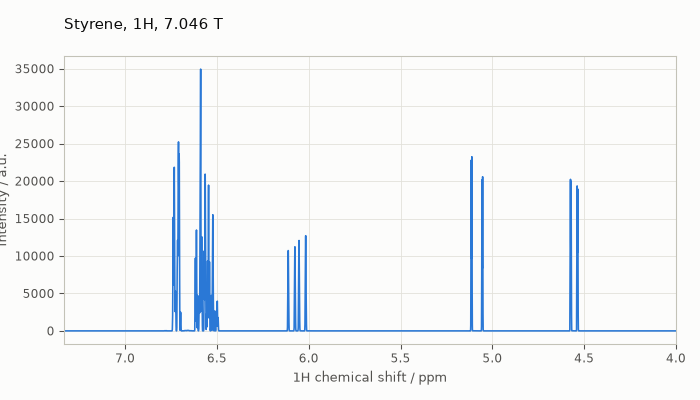

In [2]:
from spynach.plotting import plot_1d

plot_1d(spin_system, spectrum.real, parameters, title="Styrene, 1H, 7.046 T")

## General differences

| topic | Spinach | Spynach |
|---|---|---|
| spin numbers | 1-based | **0-based**: Spinach spin 1 is Spynach spin 0 |
| input structures | MATLAB structs: `sys.magnet=14.1;` | dictionaries: `sys = {"magnet": 14.1}` |
| lists | cell arrays `{'1H','13C'}` | lists `["1H", "13C"]` |
| spin system object | `spin_system` struct, copied and returned by each function | `spin_system` frozen dataclass, copied and returned by each function; the guides use the same name |
| matrix product | `A*B` | `A @ B` (`A * B` is element-wise for NumPy and SciPy arrays) |
| conjugate transpose | `A'` | `A.conj().T` |
| sparse matrices | MATLAB sparse | `scipy.sparse.csr_array` |
| time-domain results | `n x 1` column vectors | 1-D arrays of length `n` |
| function handles | `@acquire` | `spynach.acquire` |
| authors of a function | the email addresses at the end of its header | by name in its docstring (`help(spynach.propagator)`), and in [Spinach function authors](../spinach-credits.md); function names are Spinach's and carry no authors |
| units | ppm, Hz, Tesla, Bohr magneton; rad/s internally | the same |
| tolerances | `sys.tols.<name>` | `sys["tols"]["<name>"]`, same names and defaults |

The `*` versus `@` difference is the most common translation mistake,
because both run without error:

In [3]:
Lp = spynach.operator(spin_system, "L+", "1H")
Lm = spynach.operator(spin_system, "L-", "1H")
matrix_product = Lp @ Lm                 # MATLAB Lp*Lm
elementwise = Lp * Lm                    # MATLAB Lp.*Lm, a different matrix

### Keyword arguments

Spinach functions take every input positionally, so a call that does not
need an input passes `[]` in its place. Spynach keeps Spinach's argument
order for the inputs that every call needs and makes the optional ones
keyword arguments, so that `None` placeholders disappear and the call says
what each input is:

| Spinach | Spynach |
|---|---|
| `evolution(spin_system,L,coil,rho,dt,nsteps,'observable')` | `evolution(spin_system, L, rho, dt, nsteps, "observable", coil=coil)` |
| `evolution(spin_system,L,[],rho,dt,nsteps,'final')` | `evolution(spin_system, L, rho, dt, nsteps, "final")` |
| `evolution(...,destination)` | `evolution(..., destination=rho_dest)` |
| `krylov(spin_system,L,coil,rho,dt,nsteps,output)` | `krylov(spin_system, L, rho, dt, nsteps, output, coil=coil)` |
| `thermalize(spin_system,R,[],[],rho_eq,'IME')` | `thermalize(spin_system, R, "IME", rho_eq=rho_eq)` |
| `thermalize(spin_system,R,HLSPS,T,[],'dibari')` | `thermalize(spin_system, R, "dibari", H_left=HLSPS, temperature=T)` |
| `plot_2d(spin_system,spectrum,parameters,ncont,delta,k,ncol,m,signs)` | `plot_2d(spin_system, spectrum, parameters, ncont=20, delta=(...), k=2, signs="both")`, all six keyword-only, Spinach's names and defaults |

Everything else keeps Spinach's positional form: `step(spin_system, L,
rho, dt)`, `operator`, `state`, `propagator`, and the pulse-sequence
signature `sequence(spin_system, parameters, H, R, K)`, which the contexts
call positionally so that a sequence may name its arguments as it likes.

## Spin system: `sys` and `inter`

`create(sys, inter)` reads the same fields as in Spinach, with the same
meaning and units. Shown for a 1H-13C pair:

```matlab
sys.isotopes={'1H','13C'};
sys.magnet=14.1;
inter.zeeman.scalar={2.0 30.0};
inter.coupling.scalar=cell(2,2);
inter.coupling.scalar{1,2}=145;
spin_system=create(sys,inter);
```

In [4]:
sys = {"isotopes": ["1H", "13C"], "magnet": 14.1}
inter = {
    "zeeman": {"scalar": [2.0, 30.0]},
    "coupling": {"scalar": [[None, 145.0],
                            [None, None]]},
}
spin_system_hc = spynach.create(sys, inter)

- **Same:** isotope names (from Spinach's `spin.m`, including `'E'` for
  electrons), units (ppm for nuclear shifts, Bohr magneton units for
  g-values, Hz for couplings, Tesla for the field), the rule that a
  coupling entered both above and below the diagonal is summed, dropping
  of interactions below `tols.inter_cutoff`, and the internal storage of
  every interaction as a 3x3 tensor in rad/s.
- **Empty entries:** where Spinach uses empty cells (`cell(2,2)`), use
  `None` or `0`. A nested list, or a NumPy array for scalar couplings,
  are both accepted.
- **Tolerances:** `sys["tols"] = {"prop_chop": 1e-14}` does what
  `sys.tols.prop_chop=1e-14` does. The values are in `spin_system.tols`.
- **Immutability:** Spinach scripts that change a spin system after
  `create` (`spin_system.inter.coupling.matrix{1,2}=...`) must build a new
  system instead. A parameter scan is a loop over `create`:

In [5]:
for J in (140.0, 145.0, 150.0):
    spin_system_scanned = spynach.create(sys, {**inter, "coupling": {"scalar": [[0, J], [0, 0]]}})
    print(J, spin_system_scanned.coupling_matrix[0][1][0, 0] / (2 * np.pi))

140.0 140.0
145.0 145.0
150.0 150.0


- **Tensors and coordinates:** `inter.zeeman.eigs`/`euler` and
  `inter.coupling.eigs`/`euler` carry over as nested lists with `None`
  for empty cells (same units, radians for the ZYZ Euler angles);
  `inter.coordinates` (Angstrom) gives the same point dipolar couplings
  as `dipolar.m`, half the tensor in both `[n][k]` and `[k][n]`, and the
  same proximity matrix. See the [solid-state guide](solid-state.ipynb).
- **Molecule files:** Spinach's `etc/molecules/strychnine.m` is
  `spynach.molecules.strychnine(["1H"])`, returning `(sys, inter)` with the
  same shifts, couplings and coordinates (0-based spin numbers in the
  same order; `sys["magnet"]` is set by the caller as in Spinach). Only
  the proton data is ported; `["1H", "13C"]` raises `NotImplementedError`.
  The other molecule files are not ported.
- **Chemical subsystems:** `inter.chem.parts`, `inter.chem.concs`, and
  `inter.chem.rates` carry over with 0-based spin indices in `parts`; the
  validation is Spinach's (every spin in one part, no couplings between
  parts, `rates` square with zero column sums, equal isotope sequences in
  exchange mode). They are kept in `spin_system.chem` (`parts`, `concs`, `rates`).

```matlab
inter.chem.parts={1,2};
inter.chem.rates=[-2e3 2e3; 2e3 -2e3];
inter.chem.concs=[1.0 1.0];
```

In [6]:
inter_exch = {"zeeman": {"scalar": [0.0, 3.0]},
              "chem": {"parts": [[0], [1]], "rates": [[-2e3, 2e3], [2e3, -2e3]], "concs": [1.0, 1.0]}}
spin_system_exchange = spynach.create({"isotopes": ["1H", "1H"], "magnet": 14.1}, inter_exch)
print(spin_system_exchange.chem.parts)

((0,), (1,))


**Not ported yet** (each raises `NotImplementedError` naming the field):
`sys.output`, `sys.enable`/`sys.disable` tokens other than the
propagation ones listed under [Calculation modalities](#Calculation-modalities)
(so `'gpu'`, `'greedy'`, `'caching'`, ... are refused; `'greedy'` only
changes Spinach's parallelisation and can be dropped), `sys.parallel`,
`sys.scratch`, `inter.pbc` (periodic images of the
dipolar couplings), `inter.giant`, `inter.suscept`,
`inter.order_matrix`, the Lindblad/DNP relaxation fields,
`inter.chem.flux_rate`/`flux_type` (magnetisation flux), `inter.chem.rp_*`
(radical pair kinetics), and bosonic modes
(cavities, phonons, transmons). The `kinetics` superoperator itself is
not ported yet either; see [Calculation modalities](#Calculation-modalities).

## Basis: `bas`

In [7]:
bas = {"formalism": "zeeman-hilb", "approximation": "none"}
spin_system_hc = spynach.basis(spin_system_hc, bas)

- **Same:** field names and meanings: `formalism`, `approximation`,
  `inter_level`, `prox_level`, `connectivity`, `projections`,
  `longitudinal`, `zero_quantum`, `manual`. `zeeman-hilb` requires
  `approximation='none'`; basis states are Zeeman product states ordered as
  `kron(spin 1, spin 2, ...)`, so matrices are element for element
  identical to Spinach's. In `sphten-liouv` the basis descriptor
  `spin_system.basis.basis` is Spinach's `spin_system.bas.basis` (same integer
  encoding `l*l + l - m`, same lexicographic row order, unit state first),
  and `spin_system.basis.tot_proj`/`tot_cord` are `bas.tot_proj`/`bas.tot_cord`.
  Spinach 2.13 renamed `bas.level` to `inter_level`, `bas.space_level` to
  `prox_level` and `bas.longitudinals` to `longitudinal`; Spynach uses the
  new names and raises the same rename errors for the old ones.
- **Different:** spin numbers in `longitudinal`, `zero_quantum` and
  `manual` are 0-based; the per-substance cell arrays become lists with one
  entry per chemical subsystem (`projections=[[1]]` for one substance,
  `longitudinal=[["13C"], []]` for two). The proximity graph comes from
  `inter.coordinates` and `tols.prox_cutoff`, as in Spinach.

```matlab
bas.formalism='sphten-liouv';
bas.approximation='IK-2';
bas.connectivity='scalar_couplings';
bas.prox_level=1;
bas.projections={+1};
```

In [8]:
bas_ik2 = {"formalism": "sphten-liouv", "approximation": "IK-2",
           "connectivity": "scalar_couplings", "prox_level": 1, "projections": [[1]]}
spin_system_hc_liouv = spynach.basis(spin_system_hc, bas_ik2)
print(spin_system_hc_liouv.basis.basis.T)     # unit state first, then coherence order +1 only

[[0 0 1 1 2]
 [0 1 0 2 1]]


- **Not ported yet:** `zeeman-liouv`, the `IK-DNP` and `IK-SBS`
  approximations, and permutation symmetry (`sym_group`, `sym_spins`). In
  Spinach, switching a script from Hilbert to Liouville space changes only
  `bas`, and states become vectors instead of matrices; Spynach keeps that
  behaviour.

## Operators and states

The three Spinach call forms carry over; only the brackets and the spin
numbers change:

| Spinach | Spynach | result |
|---|---|---|
| `operator(spin_system,'Lz','1H')` | `spynach.operator(spin_system, "Lz", "1H")` | sum of Lz over all 1H |
| `operator(spin_system,'Lz',[1 3])` | `spynach.operator(spin_system, "Lz", [0, 2])` | Lz(1) + Lz(3) in Spinach numbering |
| `operator(spin_system,{'Lz','L+'},{1,2})` | `spynach.operator(spin_system, ["Lz", "L+"], [0, 1])` | product Lz(1) L+(2) |
| `operator(spin_system,'Lx','all')` | `spynach.operator(spin_system, "Lx", "all")` | also `'nuclei'`, `'electrons'` |
| `state(spin_system,'L+','13C')` | `spynach.state(spin_system, "L+", "13C")` | density matrix |

In Spinach a cell array of spin numbers, `{1,2}`, selects the product form.
In Spynach the type of the *first* argument does: a string gives a sum, a
list gives a product.

In [9]:
Lz_sum = spynach.operator(spin_system_hc, "Lz", [0, 1])         # Lz(H) + Lz(C)
LzSz = spynach.operator(spin_system_hc, ["Lz", "Lz"], [0, 1])   # Lz(H) Lz(C)

- **Same:** operator labels `E`, `Lx`, `Ly`, `Lz`, `L+`, `L-`, `Tl,m`;
  matrix elements (Spinach's `Lz` for spin-1/2 is `0.4999999999999999`,
  one ulp below 0.5, and Spynach reproduces it); in Hilbert space a state
  is the operator itself, unnormalised.
- **Same in Liouville space:** `operator(spin_system, ops, spins, operator_type)`
  takes Spinach's `'left'`, `'right'`, `'comm'` (default) and `'acomm'`
  and builds the superoperator in the restricted basis by the same
  structure-coefficient algorithm (`superop.m`), so matrix elements and
  the basis order match Spinach's. `state(spin_system, ops, spins, method)` has the
  `'exact'` (default), `'cheap'` and `'chem'` methods with the same
  normalisation: in `sphten-liouv` the `'exact'` coefficient of a spin-1/2
  `Lz` is 1/2, of `L+` it is `-1/sqrt(2)`.
- **Different:** `operator` has no `format` argument (`'xyz'` triplets are
  internal); `operator_type` and `method` are ignored in Hilbert space, as
  in Spinach. Liouville-space states are dense 1-D NumPy vectors rather
  than sparse `n x 1` columns.

```matlab
bas.formalism='sphten-liouv'; bas.approximation='none';
spin_system=basis(spin_system,bas);
Lz_L=operator(spin_system,'Lz','1H','left');
rho=state(spin_system,'L+','1H','cheap');
```

In [10]:
spin_system_hc_none = spynach.basis(spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none"})
Lz_L = spynach.operator(spin_system_hc_none, "Lz", "1H", "left")
rho_cheap = spynach.state(spin_system_hc_none, "L+", "1H", "cheap")
print(Lz_L.shape, rho_cheap.shape)
print(np.flatnonzero(rho_cheap), rho_cheap[rho_cheap != 0])

(16, 16) (16,)
[4] [-1.41421356+0.j]


- **Not ported yet:** labels `CT*` (central transition) and `ZL*`
  (Zeeman energy level projectors), operators on bosonic modes, and the
  `zeeman-liouv` formalism (`hilb2liouv`).

## Assumptions and the Hamiltonian

In [11]:
H = spynach.hamiltonian(spynach.assume(spin_system_hc, "nmr"))
H_zeeman = spynach.hamiltonian(spynach.assume(spin_system_hc, "nmr", "zeeman"))

- **Same:** `assume(spin_system, 'nmr')` and the retention options
  `'zeeman'` and `'couplings'`; the `'nmr'` truncation rules (strong
  coupling within an isotope, weak `LzSz` coupling between isotopes);
  rounding of every element to `tols.liouv_zero`; the dense-or-sparse
  choice by `tols.small_matrix` and `tols.dense_matrix`.
- **Same in Liouville space:** `hamiltonian(spin_system, operator_type)` with
  `'left'`, `'right'`, `'comm'` (default) or `'acomm'` returns the
  superoperator built from the same term table; `frqoffset` adds
  `2*pi*offset*[Lz, .]`; `kinetics(spin_system)` is the exchange superoperator of
  `kinetics.m` with the `L = H + 1i*R + 1i*K` convention, `equilibrate`
  solves the kinetic equilibrium as `equilibrate.m`; `trajan` returns the
  amplitudes that `trajan.m` plots (`plot_trajan` draws them) and
  `stateinfo` lists a state's largest coefficients; `correlation`
  and `coherence` zero the same states.
- **Different:** Spinach's `[H,Q]=hamiltonian(...)` becomes
  `H, Q = hamiltonian(spin_system, aniso=True)`; `Q[0]`/`Q[1]` are the rank-1 and
  rank-2 nested lists (Spinach's `Q{1}`/`Q{2}`), and
  `orientation(Q, angles)` is the same contraction with the same Wigner
  matrices. Spinach sums the Hamiltonian terms in a random order, so its
  last digits change from run to run; Spynach sums in a fixed order and
  is reproducible. `coherence`
  takes a list of `(spins, orders)` pairs instead of nested cell arrays,
  and both filters expect the spin state space on the *last* axis of a
  stacked state array.

In [12]:
spin_system_hc_liouv = spynach.assume(spin_system_hc_none, "nmr")
H_comm = spynach.hamiltonian(spin_system_hc_liouv)                  # [H, .] in Liouville space
H_left = spynach.hamiltonian(spin_system_hc_liouv, "left")
H_right = spynach.hamiltonian(spin_system_hc_liouv, "right")

- **Not ported yet:** the `'qnmr'` and DNP assumption sets (`'nmr'`,
  `'esr'`, `'deer'`, `'deer-zz'` and `'labframe'` are ported),
  magnetisation flux and radical-pair kinetics, giant-spin terms, and
  the Hilbert-space branches of `correlation` and `coherence`.

## Experiment parameters

`parameters` is a dictionary with Spinach's field names. `liquid` copies it
before filling in defaults, so the caller's dictionary is never changed,
as with MATLAB's value semantics.

| field | meaning | ported |
|---|---|---|
| `spins` | isotopes of the working channels, e.g. `["1H"]` | yes |
| `offset` | transmitter offset per channel, Hz; a number or a list | yes; default 0 |
| `sweep` | spectral width, Hz | yes |
| `npoints` | number of complex points | yes |
| `rho0`, `coil` | initial state, detection state | yes |
| `decouple` | isotopes to decouple | only empty |
| `rframes`, `needs` | extra rotating frames, context requests | only empty |
| `homodec_oper`, `homodec_pwr`, `dead_time` | `acquire` options | no |
| `zerofill`, `axis_units`, `invert_axis` | read by the plotting functions | yes, by `spynach.plotting` |

Fields that only processing and plotting functions read are accepted and
ignored by the simulation, as in Spinach.

## Calculation modalities

| Spinach | Spynach |
|---|---|
| contexts: `liquid`, `powder`, `crystal`, `singlerot`, `doublerot`, `floquet`, `gridfree`, `imaging`, ... | `liquid`, `crystal`, `powder`, `singlerot` (serial over the grid, same weighted sum; grids by their Spinach names; `singlerot` in Liouville space with the same `rate`, `axis`, `max_rank` parameters and the same Fokker-Planck layout). `powder` and `singlerot` accept an optional `parameters["progress"](../done, total)`, called after each orientation; Spinach has no equivalent |
| pulse sequences in `experiments/`: `acquire`, `hsqc`, `cosy`, `noesy`, ... | `acquire` (with `decouple`, `dead_time`, `homodec_*`), `cosy`, `noesy`, `hsqc`; others: write them the same way (see the [pulse sequence guide](pulse-sequences.ipynb)) |
| `evolution` outputs `'observable'`, `'final'`, `'total'`, `'trajectory'`, `'refocus'`, `'multichannel'` | `'observable'` in Hilbert space; all but `'total'` in Liouville space |
| `evolution(spin_system,L,coil,rho,dt,nsteps,output)` | `evolution(spin_system, L, rho, dt, nsteps, output, coil=coil)`: the detection state is a keyword, see [Keyword arguments](#Keyword-arguments) |
| `evolution(...,destination)` destination state screening | the same, Liouville space (`destination=` keyword) |
| `reduce`, `zte`, `path_trace` (trajectory-level reduction), `sys.disable={'zte','pt','dss','merge','krylov','trajlevel'}`, `sys.enable={'krylov'}` | the same, Liouville space; permutation symmetry not ported |
| `step` (single generator and 2/3-point Lie quadratures), `krylov` | the same in Liouville space; Hilbert-space `step` for one generator |
| `pulse`, `shaped_pulse_*` | not ported; use `propagator` or `step` |
| `apodisation`, `plot_2d`, `dilute`/`kill_spin`, `decouple`, `homospoil` | the same; `apodisation(fid, [("exp", 6)])` takes tuples instead of nested cells, `plot_2d` draws a Plotly contour figure with the same `ncont, delta, k, ncol, m, signs` arguments as keywords, binning spectra longer than `max_points=512` per axis (largest magnitude per bin) so that the HTML stays small |
| `propagator`: Pade `expm` below `small_matrix`, scaled and squared Taylor series above | the same |
| the sparse products of `propagator`, `step` and `clean_up` (MATLAB sparse arithmetic, `gpu` for the largest) | NumPy and SciPy, or (the default, since Numba is installed with Spynach) threaded Numba kernels (`spynach.kernels`) that multiply and round in one pass, give the same results (an element within an ulp of a rounding boundary can land on the neighbouring grid point, `1e-10` by default) and are routed through `spynach.backend` so that a GPU backend can replace them; `SPYNACH_NUMBA=0` switches them off |
| relaxation (`relaxation`, `equilibrium`, `thermalize`) | Redfield, `t1_t2`, `damp`, `SRFK`, `SRSK` with the same `inter` fields and policies (`srsk_sources` and the `srfk_mdepth` indices are 0-based); see the [relaxation guide](relaxation.ipynb); Lindblad, DNP theories, Nakajima-Zwanzig not ported |
| chemical kinetics (`kinetics`) | first-order exchange; `liquid` passes it as `K` and `acquire` propagates under `H + 1i*K` |
| parallel `evolution` (Kuprov-Edwards split), `parfor` | serial; the same numbers |
| GPU via `sys.enable={'gpu'}` | CPU only; `'gpu'` is refused with a pointer to `porting/gpu-notes.md`, where the backend plan lives |
| `sys.enable={'op_cache','ham_cache','prop_cache'}` | operators are always cached on the basis (`spin_system.basis.op_cache`, bounded, no option needed); Hamiltonians and propagators are not cached |
| Liouville-space states | dense 1-D NumPy vectors; stacks are `(nstates, k)` arrays, trajectories `(nstates, nsteps + 1)` as in Spinach |

**Pulse sequences** have Spinach's signature, `sequence(spin_system,
parameters, H, R, K)`, and are passed to `liquid` the same way. Inside,
use `spynach.operator`, `spynach.propagator`, and `spynach.evolution` as you
would in MATLAB; the Hilbert-space guide has a
[worked example](hilbert-space.ipynb#Writing-your-own-pulse-sequence).
Spinach sequences usually combine the generator as `L = H + 1i*R + 1i*K`;
in Python that is `L = H + 1j * R + 1j * K`.

**Numerical agreement** with Spinach is checked stage by stage against
stored Spinach 2.13 output; see
[Checking results against Spinach](hilbert-space.ipynb#Checking-results-against-Spinach).

## Processing and plotting

`axis_1d`, `ft_axis`, and `plot_1d` are in `spynach.plotting`, with
Spinach's arguments; the other processing helpers are a line of NumPy.

| Spinach | Spynach / NumPy |
|---|---|
| `fftshift(fft(fid,zerofill))` | `np.fft.fftshift(np.fft.fft(fid, zerofill))` |
| `apodisation(spin_system,fid,{{'exp',k}})` | `fid[0] /= 2; fid *= np.exp(-k * np.linspace(0, 1, fid.size))` |
| `apodisation(spin_system,fid,{{'gauss',k}})` | `fid[0] /= 2; fid *= np.exp(-k * np.linspace(0, 1, fid.size) ** 2)` |
| legacy `apodization(fid,'exp-1d',k)` (pre-2.9 scripts) | `spynach.apodisation(fid, [("exp", k)])`, the 2.13 form, which also halves the first point |
| `csvread('rho.csv')` of a complex column | `np.array([complex(s.replace('i', 'j')) for s in lines])`; see `examples/user_ml/zulf_pf6_1d.py` |
| `[ax,ax_label]=axis_1d(spin_system,parameters)` | `ax, ax_label = axis_1d(spin_system, parameters)` |
| `ft_axis(offset,sweep,npoints)` | `ft_axis(offset, sweep, npoints)` |
| `kfigure(); plot_1d(spin_system,spectrum,parameters)` | `plot_1d(spin_system, spectrum, parameters)` |
| `plot(fid)` of a time-domain signal | `plot_fid(fid, parameters)` |

How `plot_1d` differs from Spinach's:

- It returns a Plotly figure instead of drawing into the current MATLAB
  axes. Display it as the last expression of a notebook cell, change it
  with Plotly's methods (`fig.update_xaxes(range=[7, 6])` for `xlim`), and
  save it with `fig.write_html(...)`; `figure_png(fig)` gives PNG bytes in
  place of MATLAB's `print -dpng` (Kaleido when it can run, otherwise a
  Matplotlib redraw). There is no `kfigure`, `hold on`, or
  `varargin` of line options; to overlay spectra, pass them together as a
  list, with `names=[...]` for the legend.
- `zerofill` defaults to the length of the spectrum (Spinach: to
  `npoints`), and a `zerofill` that disagrees with the spectrum length is
  an error.
- Spinach's defaults (`axis_units='ppm'`, `invert_axis=1`, `offset=0`)
  apply without the log messages; `derivative` is not ported.
- `axis_1d` labels axes in plain text (`1H chemical shift / ppm`) rather
  than LaTeX; `plot_1d` typesets the mass number as a superscript.

Spinach's `apodisation` halves the first point of the FID by default;
apply that step yourself when comparing spectra with Spinach's.

## Checking your own workflow against Spinach

The normwise comparison behind the parity suite is a public function,
`spynach.oracle.compare`, and it takes any arrays: a result from Spynach and
the same quantity saved by your Spinach script. Save it in MATLAB with
`save('reference.mat', 'fid', '-v7')`, load it with `scipy.io.loadmat`, and
compare with the tolerance that fits the quantity (see
[Parity with Spinach](../parity.md) for the policy: 1e-14 for operators and
states, 1e-12 for Hamiltonians, 1e-9 for anything through a propagator or
an FID). Here a `.mat` file written from Python stands in for the one
from MATLAB:

In [13]:
import tempfile
from pathlib import Path

from scipy.io import loadmat, savemat

from spynach.oracle import assert_matches, compare

reference_fid = fid + 1e-12 * fid[0]                    # pretend this came from Spinach
with tempfile.TemporaryDirectory() as folder:
    savemat(Path(folder) / "reference.mat", {"fid": reference_fid})   # MATLAB: save('reference.mat', 'fid', '-v7')
    ref = loadmat(Path(folder) / "reference.mat")
result = compare(fid, ref["fid"].ravel(), rtol=1e-9, atol=0, name="fid")   # MATLAB saves a 1 x n row
print(result)
print(result.passed, result.rel_err)

PASS fid (2048,): rel_err=6.227e-12 max_abs_err=5.120e-10 ref_norm=3.721e+03 (rtol=1e-09, atol=0)
True 6.226668068137977e-12


`assert_matches` takes the same arguments and raises `AssertionError` with
that one-line report when the comparison fails, for use in your own tests.
The full-size example scripts in `examples/` do this for whole experiments
with `--compare FILE.mat`, and [`comparison/README.md`](../../comparison/README.md)
is the protocol for a timed and profiled comparison of both sides with an
HTML report.

## Beyond the port

This guide lists what carries over and what is still missing. What Spynach
has and Spinach does not is collected, with examples, in
[Beyond the port](beyond-the-port.ipynb): the coherence-transfer-pathway module
`ctps` with its non-ideal pulse model and cogwheel search, the interactive
figures and `figure_png`, `compare` and the parity page, and the executable
documentation.

## Messages and errors

- Spinach prints a running log (`report`) and summary tables. Spynach is
  silent; warnings, such as a time step much longer than the system's
  dynamics, go to Python's `logging` module under the name `"spynach"`.
- Spinach's input checks (`grumble`) become `ValueError` for invalid input.
- Anything that Spinach supports and Spynach does not yet raises
  `NotImplementedError` with a message naming the missing piece. Spynach
  never silently ignores an input it does not understand.

In [14]:
try:
    spynach.create({"isotopes": ["1H"], "magnet": 14.1, "output": "hush"}, {})
except NotImplementedError as error:
    print(error)

sys field(s) ['output'] not ported yet; supported: ['disable', 'enable', 'isotopes', 'labels', 'magnet', 'tols']
